This notebook accompanies [09-variational-monte-carlo](https://xing-phys.github.io/ai-for-physics/09-variational-monte-carlo.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Variational Monte Carlo: turning a wavefunction into a scientific calculation 

A neural wavefunction is useful only if we can answer physical questions with it. Which configuration contributes to the energy? How can the parameters improve without knowing the exact ground state? How many samples are enough? Variational Monte Carlo (VMC) joins three ideas: the variational principle selects an objective, Monte Carlo estimates the required averages, and differentiable parametrizations permit optimization. None of these ideas is specific to neural networks. Their combination makes large neural trial states practical.

The physical motivation is to replace a sum over all configurations by a statistically controlled sample of configurations that matter for the trial state. We will derive the estimator, its gradient, and the geometry-aware update called stochastic reconfiguration. We will also identify precisely which errors statistical error bars do and do not measure.

::: {.callout-note title="Learning goals and prerequisites"}
Read [Quantum foundations](07-quantum-foundations.ipynb) for the energy bound and [Neural quantum states](08-neural-quantum-states.ipynb) for amplitudes and sampling distributions. We use expectations, variances, derivatives, and linear systems. After this chapter you should be able to implement a small VMC solver, derive its energy gradient, diagnose autocorrelation, and explain regularization of the variational metric. [Quantum dynamics](10-quantum-dynamics.ipynb) interprets the same metric as a projection of the Schrödinger equation.
:::

## The local energy and why the normalization cancels 

Let $\widetilde\psi_\theta(s)$ be an unnormalized trial amplitude, $Z=\sum_s|\widetilde\psi(s)|^2$, and $p(s)=|\widetilde\psi(s)|^2/Z$. Initially assume nonzero amplitude on the whole relevant basis. Inserting basis states into the Rayleigh quotient gives

$$
E=\frac1Z\sum_s\widetilde\psi(s)^*\sum_{s'}H_{ss'}\widetilde\psi(s')
=\sum_sp(s)E_{\mathrm{loc}}(s),
$$

where

$$
E_{\mathrm{loc}}(s)=\frac{(H\widetilde\psi)(s)}{\widetilde\psi(s)}
=\sum_{s'}H_{ss'}\frac{\widetilde\psi(s')}{\widetilde\psi(s)}.
$$ 

The amplitude scale cancels from every ratio. We do not have to compute $Z$ if we can sample $p$. For a Hermitian Hamiltonian the exact expectation $E$ is real, although $E_{\mathrm{loc}}(s)$ can be complex at individual configurations. In computation we average its real part and use a persistent nonzero imaginary average as a possible sampling or implementation diagnostic.

For a periodic transverse-field Ising chain with $N\geq3$ and one term per bond,

$$
H=-J\sum_{i=1}^N\sigma_i^z\sigma_{i+1}^z-h\sum_{i=1}^N\sigma_i^x,
\qquad \sigma_{N+1}^z=\sigma_1^z,
$$

the diagonal contribution is $-J\sum_i s_is_{i+1}$. The only off-diagonal connections flip one spin. Thus

$$
E_{\mathrm{loc}}(s)=-J\sum_i s_is_{i+1}
-h\sum_i\frac{\widetilde\psi(s^{(i)})}{\widetilde\psi(s)}.
$$ 

There are $N$ ratios rather than $2^N$ summands. A complicated ansatz may still make each ratio costly, but the sparse Hamiltonian is what makes the estimator possible. The $N=2$ periodic formula counts two bonds between the same sites; the one-bond example in the foundations chapter intentionally used a different convention.

Nodes require care. An exact zero has zero sampling probability, so its local energy is undefined. The energy identity can still be understood by restricting the outer sum to supported configurations because their zero coefficients contribute no energy. However identities involving $H^2$, and parameter derivatives that open previously absent support, need additional terms or limiting arguments. In this chapter we assume full support in an invariant physical sector. Hard constraints are safe when the Hamiltonian preserves that sector and parameters do not change the support. In a continuum, nodal sets can have measure zero while causing large ratios near them, so finite moments must still be checked.

## Sampling a trial state 

An autoregressive state supplies direct draws. A general unnormalized state can be sampled by Metropolis–Hastings. From configuration $s$, propose $s'$ using a normalized proposal probability $q(s'\mid s)$. Accept the proposal with probability

$$
A(s\to s')=\min\left(1,\frac{p(s')q(s\mid s')}{p(s)q(s'\mid s)}\right).
$$ 

To see why this works, multiply by $p(s)q(s'\mid s)$. The accepted probability flux equals the minimum of the forward and reverse proposal fluxes. It is therefore unchanged on exchanging $s$ and $s'$. This is detailed balance. Summing the fluxes, including rejected proposals that leave the state unchanged, establishes stationarity of $p$. Normalization cancels in the ratio. A symmetric single-spin proposal gives $A=\min[1,|\widetilde\psi(s')/\widetilde\psi(s)|^2]$.

Stationarity is not the same as useful mixing. The chain must reach all supported configurations and lose memory of its starting state. If total magnetization is fixed, a single-spin flip leaves the allowed sector and is always rejected. An exchange proposal that swaps opposite spins is appropriate instead. If the model has separated probability modes, local proposals can remain trapped for a long time. A high acceptance rate alone does not prove good sampling: making tiny moves can produce nearly certain acceptance with very slow exploration.

An initial *burn-in* period is discarded while the chain approaches stationarity. After updating parameters, the target distribution changes; old samples are not automatically equilibrium samples of the new state. One may continue chains with re-equilibration, use importance weights with overlap diagnostics, or sample directly from an autoregressive model. Independent chains started in physically different regions help reveal trapping, although agreement is not a proof against a shared failure.

## Statistical uncertainty is a physical diagnostic 

For independent samples $s^{(1)},\ldots,s^{(M)}$, the estimator $\widehat E=M^{-1}\sum_mE_{\mathrm{loc}}(s^{(m)})$ has variance $\sigma_E^2/M$, provided the single-sample variance exists. For a real observable $X_m$ from a stationary Markov chain, define lag covariance $C(k)=\operatorname{Cov}(X_m,X_{m+k})$ and $\rho(k)=C(k)/C(0)$. Expanding the variance of a sum gives

$$
\operatorname{Var}(\overline X)=\frac{C(0)}{M}
\left[1+2\sum_{k=1}^{M-1}\left(1-\frac{k}{M}\right)\rho(k)\right].
$$ 

There are $M-k$ pairs at lag $k$, which explains the factor $1-k/M$. If correlations decay sufficiently rapidly and $M$ is large, define

$$
\tau_{\mathrm{int}}=\frac12+\sum_{k=1}^\infty\rho(k),\qquad
M_{\mathrm{eff}}\simeq\frac{M}{2\tau_{\mathrm{int}}}.
$$

The standard error is approximately $\sqrt{C(0)/M_{\mathrm{eff}}}$. Some authors define the autocorrelation time with the factor of two absorbed; report the convention. Autocorrelation is observable dependent. Energy may decorrelate faster than an order parameter that distinguishes two modes, so energy error bars alone do not certify a phase diagnosis.

In *blocking*, divide a long sequence into contiguous blocks, calculate a mean for each block, and estimate uncertainty from those block means. Increase the block length until the estimated error stabilizes while enough blocks remain. Failure to find a plateau warns that the run may be too short. Randomly shuffling samples before blocking destroys the correlation information and produces an unjustifiably optimistic answer.

Sampling error is only one part of the error budget. *Variational bias* arises because the ansatz may not contain the true state. *Optimization error* arises because training may not reach the best available state. Finite size, approximate Hamiltonians, and discretization add physical-model errors. More samples reduce sampling error, but do not eliminate these other sources. Final observables should be evaluated in a separate stationary run with parameters fixed, not pooled across a changing optimization trajectory.

## Deriving the energy gradient 

Let every parameter $\theta_k$ be real; a complex network can always be described by the real and imaginary parts of its coefficients. Define the logarithmic derivative

$$
O_k(s)=\partial_{\theta_k}\log\widetilde\psi_\theta(s)
=\frac{\partial_{\theta_k}\widetilde\psi_\theta(s)}{\widetilde\psi_\theta(s)}.
$$

Differentiate the numerator $\mathcal N=\langle\widetilde\psi|H|\widetilde\psi\rangle$. Hermiticity makes its two derivative terms complex conjugates, so

$$
\partial_k\mathcal N
=2\operatorname{Re}\langle\partial_k\widetilde\psi|H|\widetilde\psi\rangle
=2Z\operatorname{Re}\langle O_k^*E_{\mathrm{loc}}\rangle_p.
$$

Similarly, $\partial_kZ=2Z\operatorname{Re}\langle O_k^*\rangle_p$. Applying the quotient rule yields

$$
\partial_kE=2\operatorname{Re}\left[
\langle O_k^*E_{\mathrm{loc}}\rangle_p
-\langle O_k^*\rangle_p\langle E_{\mathrm{loc}}\rangle_p\right].
$$ 

We obtained the derivative without differentiating $E_{\mathrm{loc}}$ explicitly. A tempting but wrong shortcut is to differentiate only the local energy while treating the sampled distribution as fixed. Its parameter dependence is essential. Automatic differentiation through a discrete random draw also does not by itself reproduce this covariance estimator.

Define the centered variables $\Delta O_k=O_k-\langle O_k\rangle$ and $\Delta E=E_{\mathrm{loc}}-E$, and the force $F_k=\operatorname{Re}\langle\Delta O_k^*\Delta E\rangle$. Then the real parameter gradient is $2F_k$. A constant shift $H\mapsto H+cI$ leaves $\Delta E$ and the gradient unchanged, as it must. Subtracting the mean energy also acts as a variance-reducing baseline.

Finite-sample covariance estimates have small estimator biases depending on whether one divides by $M$ or $M-1$. In optimization, Monte Carlo noise and changing parameters generally matter more than this distinction. For reported final uncertainties, define the estimator and use enough independent or effectively independent data to validate it. Robust clipping can stabilize training when rare ratios dominate, but clipped estimators are biased and should not replace an unclipped final energy evaluation.

## Stochastic reconfiguration from wavefunction distance 

Ordinary gradient descent treats equal coordinate changes as equally large. But one parameter may change the physical state much more than another, and redundant parameters may change nothing. We need a distance between normalized states. Let $|\psi\rangle=|\widetilde\psi\rangle/\sqrt Z$ and remove the component of a parameter derivative parallel to the state:

$$
|D_k\psi\rangle=(I-|\psi\rangle\langle\psi|)\partial_k|\psi\rangle.
$$

In the configuration basis, this tangent vector has coefficients $\psi(s)\Delta O_k(s)$. To second order, the physically relevant squared displacement under a small real parameter change is

$$
ds^2=\sum_{kl}d\theta_kS_{kl}d\theta_l,
\qquad
S_{kl}=\operatorname{Re}\langle\Delta O_k^*\Delta O_l\rangle.
$$ 

This is the real quantum geometric metric for these coordinates. It is positive semidefinite because $v^TSv=\langle|\sum_kv_k\Delta O_k|^2\rangle\geq0$ for every real vector $v$. A global amplitude scale or global phase has constant $O_k$, hence zero centered derivative and zero metric length.

To derive an update, imagine a short normalized imaginary-time step,

$$
|\psi\rangle\mapsto|\psi\rangle-\eta(H-E)|\psi\rangle.
$$

Approximate it by a tangent displacement $\sum_k\delta\theta_k|D_k\psi\rangle$ and minimize the squared norm of their difference. Differentiating the quadratic function with respect to $\delta\theta_k$ gives

$$
\sum_l S_{kl}\delta\theta_l=-\eta F_k.
$$ 

This is stochastic reconfiguration (SR). The factor-of-two convention is now explicit: the gradient is $2F$, while the imaginary-time projection uses $F$. A learning-rate redefinition can absorb a factor of two, but mixing conventions when comparing real and imaginary time leads to mistakes.

The exact metric may be singular because of redundant parameters. Its sample estimate has an algebraic rank bound set by the raw sample count $M$, whether or not those samples are independent. For $P$ real logarithmic-derivative features, centering gives rank at most $\min(P,M-1)$. For complex derivatives and real parameter coordinates, stacking real and imaginary parts gives the bound $\min(P,2(M-1))$. Autocorrelation reduces statistical information and increases uncertainty; the effective independent sample count does not impose an additional algebraic rank bound. A common regularization solves $(S+\lambda I)\delta\theta=-\eta F$ with $\lambda>0$, or uses a scaled diagonal shift. Small metric eigenvalues amplify noise, while too large a shift suppresses the geometric adaptation. Check sensitivity to $\lambda$, batch size, and step size. Solving a noisy linear system to an extremely small numerical residual does not make its physical solution accurate.

For $P$ parameters, storing a dense $S$ costs order $P^2$. Instead its action on a vector can be computed from centered derivatives without forming the matrix. If $A$ is the sample-by-parameter derivative matrix with suitable normalization, $S=A^TA$ for real states and derivatives. The identity

$$
(A^TA+\lambda I)^{-1}A^T
=A^T(AA^T+\lambda I)^{-1}
$$

follows by multiplying $(A^TA+\lambda I)A^T=A^T(AA^T+\lambda I)$ by the two inverses. It converts a parameter-space solve into a sample-space solve. For complex derivatives and real parameters, stack their real and imaginary parts to obtain the corresponding real matrix. This linear-algebra idea underlies minimum-step SR methods; the actual choices of pseudoinverse, damping, and noise control matter in a large implementation [@q-chen2024].

## Worked continuum example: the harmonic oscillator 

Use units $\hbar=m=\omega=1$, with $H=-\frac12d^2/dx^2+x^2/2$, and trial amplitude $\widetilde\psi_\alpha(x)=e^{-\alpha x^2/2}$ for $\alpha>0$. Differentiating twice gives $\widetilde\psi''/\widetilde\psi=\alpha^2x^2-\alpha$, so

$$
E_{\mathrm{loc}}(x)=\frac\alpha2+\frac{1-\alpha^2}{2}x^2.
$$

The normalized sampling distribution is $p(x)=\sqrt{\alpha/\pi}e^{-\alpha x^2}$. Gaussian integration gives $\langle x^2\rangle=1/(2\alpha)$ and $\langle x^4\rangle=3/(4\alpha^2)$. Therefore

$$
E(\alpha)=\frac14\left(\alpha+\frac1\alpha\right)\geq\frac12,
\quad O_\alpha=-\frac{x^2}{2},\quad
S=\frac{1}{8\alpha^2},\quad F=\frac{\alpha^2-1}{8\alpha^2}.
$$

The energy minimum is at $\alpha=1$, and $2F=(1-\alpha^{-2})/4$ agrees with direct differentiation. SR gives $\dot\alpha=-F/S=1-\alpha^2$ in imaginary time. It increases a too-wide wavefunction's inverse width and decreases a too-narrow one's inverse width. At $\alpha=1$, the local energy is identically $1/2$ at every sampled position. This is the zero-variance property of an exact eigenstate.

Under full support and finite moments, $\langle|E_{\mathrm{loc}}-E|^2\rangle=\langle H^2\rangle-E^2$, since the numerator is $\sum_s|(H-E)\psi(s)|^2$. Thus a good eigenstate can have very low energy-estimator variance. Low variance alone does not certify that it is the ground state, and sample estimates can miss rare high-energy regions.

## An executable Ising VMC laboratory 

We use a single-parameter Jastrow amplitude $\widetilde\psi_\theta(s)=\exp[\theta B(s)]$, $B=\sum_is_is_{i+1}$. Flipping $i$ changes $B$ by $-2s_i(s_{i-1}+s_{i+1})$, so every local-energy ratio is explicit. Enumeration lets us test the energy, its derivative, and a Monte Carlo error estimate against exact sums. The family is intentionally limited: its best energy remains above the exact ground energy.

In [1]:
import itertools
import numpy as np
rng = np.random.default_rng(2026)
N, J, h = 6, 1.0, 0.8
states = np.array(list(itertools.product([-1., 1.], repeat=N)))
B = np.sum(states * np.roll(states, -1, axis=1), axis=1)
delta_B = -2 * states * (np.roll(states, 1, axis=1)
                         + np.roll(states, -1, axis=1))
def evaluate(theta):
    logw = 2 * theta * B
    p = np.exp(logw-logw.max()); p /= p.sum()
    local = -J*B - h*np.exp(theta*delta_B).sum(axis=1)
    energy = p @ local
    force = p @ ((B-p@B)*(local-energy))
    metric = p @ (B-p@B)**2
    return energy, force, metric, p, local
theta = 0.21
energy, force, metric, p, local = evaluate(theta)
eps = 1e-6
derivative = (evaluate(theta+eps)[0]-evaluate(theta-eps)[0])/(2*eps)
assert np.allclose(derivative, 2*force, rtol=1e-7)
# A dense Hamiltonian supplies an independent physical benchmark.
index = {tuple(s): i for i, s in enumerate(states)}
H = np.diag(-J*B)
for row, s in enumerate(states):
    for site in range(N):
        flipped = s.copy(); flipped[site] *= -1
        H[row, index[tuple(flipped)]] -= h
psi = np.sqrt(p)
assert np.allclose(psi @ H @ psi, energy)
ground = np.linalg.eigvalsh(H)[0]
assert energy >= ground - 1e-12
draws = rng.choice(len(states), size=40000, p=p)
sample = local[draws]
standard_error = sample.std(ddof=1)/np.sqrt(len(sample))
print(f"Variational E: {energy:.6f}; exact ground E: {ground:.6f}")
print(f"Sample E: {sample.mean():.6f} +/- {standard_error:.6f} (one SE)")
print(f"Gradient check: {2*force:.6f} versus {derivative:.6f}")

Variational E: -6.459181; exact ground E: -7.048804
Sample E: -6.459243 +/- 0.004882 (one SE)
Gradient check: -4.283609 versus -4.283609


A particular random estimate need not lie within one standard error; under a good Gaussian approximation that interval covers the true mean in roughly 68 percent of repeated runs. Do not write a fragile assertion that demands every random run fall inside it. The deterministic assertions above test exact identities instead.

To turn this laboratory into optimization, repeatedly compute $F,S$ and update $\theta\leftarrow\theta-\eta F/(S+\lambda)$. Start with a small step, check energy reduction using exact sums, then replace those sums by direct draws. Finally replace direct draws by a Markov chain and quantify the additional correlation. This sequence isolates optimization, sampling, and implementation effects before combining them in a neural solver.

### Training a complete small RBM

We can now assemble an actual neural variational calculation. The following laboratory uses the real RBM derived in the preceding chapter, four spins, and four hidden units. Its 24 parameters are the visible biases, hidden biases, and connection weights. We enumerate all sixteen configurations to compute exact expectations during training. Thus the optimization tests the same covariance formulas as VMC while removing sampling noise; the final measurement uses Born samples. Increasing the number of spins would require replacing enumeration, not changing the physical objective.

At each iteration the algorithm evaluates all log amplitudes, subtracts their maximum for numerical stability, forms normalized Born weights, computes the Hamiltonian ratios, and contracts centered derivatives to form $F$ and $S$. It then solves a regularized linear system. The calculation contains no labeled ground-state amplitudes: the Hamiltonian is the training signal. The exact diagonalization is used only to assess the resulting answer.

RBM energy: -4.75585178; exact: -4.75585178
Independent-sample estimate: -4.75585178 +/- 0.00000000


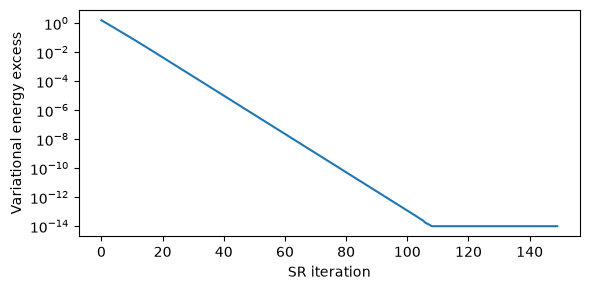

In [2]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
rng_rbm = np.random.default_rng(73)
nspin, nhidden = 4, 4
configs = np.array(list(itertools.product([-1., 1.], repeat=nspin)))
lookup = {tuple(s): i for i, s in enumerate(configs)}
bond = np.sum(configs*np.roll(configs, -1, axis=1), axis=1)
flips = np.array([[lookup[tuple(np.where(np.arange(nspin)==i, -s, s))]
                   for i in range(nspin)] for s in configs])
ham = np.diag(-bond)
for row in range(len(configs)):
    ham[row, flips[row]] -= 0.8
e0 = np.linalg.eigvalsh(ham)[0]
parameters = np.concatenate([np.zeros(nspin+nhidden),
                            0.1*rng_rbm.normal(size=nspin*nhidden)])
def rbm_measure(parameters):
    a = parameters[:nspin]
    b = parameters[nspin:nspin+nhidden]
    W = parameters[nspin+nhidden:].reshape(nspin, nhidden)
    hidden_field = configs @ W + b
    logpsi = configs @ a + np.logaddexp(hidden_field, -hidden_field).sum(axis=1)
    psi = np.exp(logpsi-logpsi.max())
    prob = psi**2; prob /= prob.sum()
    local_energy = -bond - 0.8*(psi[flips]/psi[:, None]).sum(axis=1)
    hidden_derivative = np.tanh(hidden_field)
    connection_derivative = (configs[:, :, None]*hidden_derivative[:, None, :])
    O = np.concatenate([configs, hidden_derivative,
                        connection_derivative.reshape(len(configs), -1)], axis=1)
    centered = O - prob @ O
    energy = prob @ local_energy
    force = centered.T @ (prob*(local_energy-energy))
    metric = centered.T @ (prob[:, None]*centered)
    return energy, force, metric, prob, local_energy
history = []
for iteration in range(150):
    energy, force, metric, prob, local_energy = rbm_measure(parameters)
    history.append(energy)
    direction = np.linalg.solve(metric+1e-3*np.eye(len(parameters)), force)
    parameters -= 0.05*direction
energy, force, metric, prob, local_energy = rbm_measure(parameters)
assert energy >= e0-1e-10
assert energy < history[0]
draws = rng_rbm.choice(len(configs), size=20000, p=prob)
measured = local_energy[draws]
se = measured.std(ddof=1)/np.sqrt(len(measured))
print(f"RBM energy: {energy:.8f}; exact: {e0:.8f}")
print(f"Independent-sample estimate: {measured.mean():.8f} +/- {se:.8f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(np.maximum(np.array(history)-e0, 1e-14))
ax.set(xlabel="SR iteration", ylabel="Variational energy excess")
fig.tight_layout()
plt.show()

The regularization and step size are chosen for this small demonstrator, not as universal defaults. Replacing the exact contractions by samples changes the rank and noise of the metric, so those choices must be reconsidered. An energy decrease confirms that this particular model learned useful correlations. It does not prove convergence to the best state in the family. Try several hidden-unit counts and seeds, and compare transverse as well as longitudinal correlations. These comparisons turn an optimizer demonstration into a miniature research calculation.

## Research bridge: an optimizer is part of the physics evidence 

Stochastic reconfiguration predates neural quantum states and arose within many-body variational Monte Carlo [@q-sorella2001]. Neural wavefunctions changed the size and flexibility of the parametrization [@q-carleo2017]. Large modern networks make metric storage and noisy linear solves central bottlenecks. Minimum-step SR demonstrates how sample-space formulations can enable much larger trial states and reports evidence concerning frustrated magnets [@q-chen2024]. The physical phase conclusions remain numerical evidence, with finite-size and variational qualifications, rather than consequences of the linear-algebra identity alone.

[NetKet's implementation](https://github.com/netket/netket) supplies many of these ingredients, including automatic derivatives, symmetry handling, and sampling [@q-netket2022]. The [MinSR reference implementation](https://github.com/ChenAo-Phys/MinSR) accompanies the large-network optimization work. They are useful research references after understanding the small laboratory. A software package cannot choose a reliable physical sector, establish a thermodynamic limit, or decide whether a learned sign pattern is correct for the user. Record the software version, architecture, random seeds, training schedule, sampling diagnostics, and final independent measurements.

A persuasive discovery should survive several changes that affect numerical bias: a larger ansatz, alternative initial states, more samples, a different regularization, and, where possible, a competing method. If two candidate phases have energy differences smaller than unresolved bias, the scientifically justified result is an unresolved competition. Reporting that uncertainty is more informative than assigning a phase from the lowest noisy training trace.

## Exercises and selected solutions 

1. Derive the Ising local energy for an open chain and identify the endpoint changes in the Jastrow flip formula.
2. A stationary energy chain has $\rho(k)=r^k$ for $0<r<1$. Derive $M_{\mathrm{eff}}$ and evaluate it for $r=0.9$ and $M=19000$.
3. Derive $F$ and $S$ for the harmonic-oscillator ansatz using Gaussian moments. Check that the gradient vanishes at the exact state.
4. Implement ten SR steps in the enumerated Ising laboratory. Then increase the step size until energy rises. Explain why a differential projection does not guarantee an arbitrarily large finite step is beneficial.
5. Derive the algebraic rank bounds for a metric estimated from $M$ raw samples, first for real logarithmic derivatives and then for complex derivatives with real parameter coordinates. Explain why autocorrelation changes statistical uncertainty without replacing $M$ by $M_{\mathrm{eff}}$ in those bounds. What physical redundancies can make the metric singular even with infinitely many samples?
6. Construct a two-dimensional Hilbert-space example with a trial state supported on only one basis vector. Show why sampled local-energy variance can be zero even when $\operatorname{Var}(H)$ is nonzero.

::: {.callout-tip title="Worked solutions"}
For exercise 2, $\sum_{k\geq1}r^k=r/(1-r)$, so $2\tau_{\mathrm{int}}=(1+r)/(1-r)$ and $M_{\mathrm{eff}}\simeq M(1-r)/(1+r)$. The stated run has only about 1000 independent-sample equivalents. Treating all 19000 values as independent underestimates the standard error by $\sqrt{19}$.

For exercise 5, let $X_{mk}=[O_k(s^{(m)})-\overline O_k]/\sqrt M$. For real $X$, the metric is $X^TX$. The centered rows sum to zero, so $\operatorname{rank}S\leq\min(P,M-1)$. For complex $X$ and real coordinates, write $X=A+iB$. Then $S=\operatorname{Re}(X^\dagger X)=A^TA+B^TB$, the Gram matrix of the vertically stacked real matrix with blocks $A$ and $B$. Each block has rank at most $M-1$, giving $\operatorname{rank}S\leq\min(P,2(M-1))$. The complex Hermitian covariance $X^\dagger X$ instead has complex rank at most $M-1$. Correlation can make these estimates noisy or nearly singular but does not force rank below $M_{\mathrm{eff}}$; distinct correlated rows can remain linearly independent. An overall amplitude scale, global phase, or redundant network parameter can create an exact null direction even at infinite sample count.

For exercise 6, choose $|\psi\rangle=|0\rangle$ and $H=\sigma^x$. The only sampled configuration is 0 and its local energy is $H_{00}=0$, hence its sampled variance is zero. But $H|0\rangle=|1\rangle$, so $\langle H^2\rangle=1$. The missing contribution lies at a zero-amplitude configuration. This is why the support condition in the zero-variance identity is substantive.
:::